# AI 기반 자율주행 보안 로봇의 최적 순찰 경로 설계
### 사색의 광장 · A*와 시야(FOV)를 활용한 커버리지 기반 순찰 시뮬레이션
## 목차
1. 프로젝트 소개와 문제 정의
2. 목표와 추진 과정
3. 알고리즘 선정과 설계
4. 실행 방법 및 실험 설정
5. 단계별 구현
6. 기존 실행 결과 및 평가
7. 한계, 개선 방향 및 의의
8. 자료 출처

## 1. 프로젝트 소개와 문제 정의

현장 조사에 따르면 사색의 광장의 방범 로봇은 외곽 테두리를 반복적으로 이동하는 방식으로 순찰하고 있었습니다. 이러한 경로는 내부 공간과 구조물 주변을 충분히 관찰하기 어려워 공백이 생길 수 있습니다.

본 프로젝트는 로봇의 하드웨어를 변경하기보다 순찰 경로를 개선하여 사각지대를 줄이고 감시 효율을 높이는 문제에 집중했습니다.

사색의 광장에서 로봇이 이동 가능한 구역을 폭넓게 관찰하면서 불필요한 이동을 줄이려면, 어떤 순서로 어디를 순찰해야 할까요?

단순히 출발점에서 목적지까지 짧게 이동하는 것과 공간 전체를 관찰하는 것은 서로 다른 문제입니다. 따라서 지점 간 이동에는 A*를, 다음 관측 지점 선택에는 시야를 고려한 탐욕적 커버리지 계획을 결합했습니다.

## 2. 목표와 추진 과정

### 프로젝트 목적
- 외곽 중심 순찰에서 놓치는 내부 구역을 포함해 감시 범위를 확대합니다.
- 지도상의 이동 불가능 구역을 반영하여 순찰 경로를 생성합니다.
- 이동 거리, 소요시간, 커버리지 및 경로 중복 정도로 결과를 평가합니다.
- 캠퍼스의 실제 문제를 공간 모델링과 알고리즘으로 해결하는 절차를 제시합니다.

### 진행 과정
| 단계 | 수행 내용 | 산출물 |
|---|---|---|
| 현황 조사 | 기존 순찰 방식 및 공간 구조 파악 | 문제 정의 |
| 알고리즘 조사 | Dijkstra, A*, D*, DWA의 특징 비교 | A* 선정 근거 |
| 공간 모델링 | 지도 검토, 현장 실측, 도안 및 좌표 정리 | 장애물 다각형과 격자 지도 |
| 초기 구현 | A*로 지점 간 최단 경로 탐색 | 이동 경로 |
| 개선 | 센서 거리·시야각, 관측 후보, 탐욕적 선택 결합 | 커버리지 기반 순찰 경로 |
| 평가 | 거리·시간·관측률·중복률 해석 | 시뮬레이션 평가 |

## 3. 알고리즘 선정과 설계

### 알고리즘 비교
| 알고리즘 | 특징 |
|---|---|
| Dijkstra | 누적 비용 기준으로 최단 경로 탐색 |
| A* | 누적 비용에 목표까지의 휴리스틱을 더해 탐색 |
| D* | 환경 변화에 맞춘 경로 재계획에 활용 |
| DWA | 속도·회전 속도 후보를 평가하는 지역적 주행 계획 |

## 4. 변수 설정
| 변수 | 기본값 | 의미 |
|---|---:|---|
| width / height | 169 / 111 m | 모델링한 공간 크기 |
| resolution | 0.5 m/셀 | 셀 한 변의 실제 길이 |
| sensor_range | 3 m | 관측 반경 |
| fov_deg | 120° | 부채꼴 시야각 |
| stride_cells | 4 | 후보 위치의 격자 간격(2 m) |
| orientations | 4 | 위치별 후보 방향(90° 간격) |
| top_k | 8 | A*로 정밀 평가할 후보 수 |
| start_m | (5, 5) m | 요청 시작 위치 |
| max_iter | 5,000 | 반복 횟수 상한 |

## 5. 단계별 구현

### 1. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
import heapq, math, time
from collections import deque

### 2. 실험 매개변수 설정

지도 크기와 해상도, 센서 시야, 후보 샘플링, 시작점, 반복 상한을 정의합니다. 해상도가 작아질수록 세밀하지만 셀 수와 계산량이 증가합니다.

In [2]:
width  = 169.0
height = 111.0
resolution = 0.5        # meters per cell; increase to 1.0 for much faster but coarser
sensor_range = 3.0      # meters
fov_deg = 120.0
fov_rad = math.radians(fov_deg)

# Candidate sampling and scoring
stride_cells = 4        # major speed knob (4 -> fewer candidates than 2)
orientations = 4        # reduce from 8 to 4 (45deg->90deg) for speed
top_k = 8               # only run expensive A* on top_k candidates per iteration

# start (meters)
start_m = (5.0, 5.0)

# safety
max_iter = 5000

### 3. 격자 초기화
사색의 광장 모습을 구현합니다. 행은 y 방향, 열은 x 방향입니다. 222행 × 338열 배열을 만들며 0은 이동 가능, 1은 장애물입니다.

In [3]:
W = int(width / resolution)
H = int(height / resolution)
grid = np.zeros((H, W), dtype=np.uint8)

### 4. 장애물 좌표 정의

사색의 광장 모양을 본딴 그대로 직사각형·삼각형 등 총 28개의 다각형을 미터 단위 꼭짓점으로 지정합니다. 상단의 대칭 구조도 좌표로 직접 입력되어 있습니다.

In [4]:
obstacles = {
    "rect1":  {"points":[(13,0),(13,15),(28,15),(28,0)]},
    "rect2":  {"points":[(28,0),(28,5),(73,5),(73,0)]},
    "rect3":  {"points":[(33,5),(33,10),(73,10),(73,5)]},
    "rect4":  {"points":[(13,20),(35,20),(35,32),(13,32)]},
    "rect5":  {"points":[(13,37),(13,47),(35,47),(35,37)]},
    "rect6":  {"points":[(40,15),(73,15),(73,31),(40,31)]},
    "rect7":  {"points":[(50,55.5),(50,40.5),(113,40.5),(113,55.5)]},
    "rect8":  {"points":[(83,31),(83,15),(116,15),(116,31)]},
    "rect9":  {"points":[(119,31),(119,15),(135,15),(135,31)]},
    "rect10": {"points":[(83,10),(83,0),(152,0),(152,10)]},
    "rect11": {"points":[(134,55.5),(134,45),(169,45),(169,55.5)]},
    "tri1":   {"points":[(152,10),(152,0),(164,0)]},
    "tri2":   {"points":[(139,15),(150,15),(139,26)]},
    "tri3":   {"points":[(134,40),(169,40),(169,5)]},
    # upper symmetric
    "rect1_u":  {"points":[(13,111),(13,96),(28,96),(28,111)]},
    "rect2_u":  {"points":[(28,111),(28,106),(73,106),(73,111)]},
    "rect3_u":  {"points":[(33,106),(33,101),(73,101),(73,106)]},
    "rect4_u":  {"points":[(13,91),(35,91),(35,79),(13,79)]},
    "rect5_u":  {"points":[(13,74),(13,64),(35,64),(35,74)]},
    "rect6_u":  {"points":[(40,96),(73,96),(73,80),(40,80)]},
    "rect7_u":  {"points":[(50,55.5),(50,70.5),(113,70.5),(113,55.5)]},
    "rect8_u":  {"points":[(83,80),(83,96),(116,96),(116,80)]},
    "rect9_u":  {"points":[(119,80),(119,96),(135,96),(135,80)]},
    "rect10_u": {"points":[(83,101),(83,111),(152,111),(152,101)]},
    "rect11_u": {"points":[(134,55.5),(134,66),(169,66),(169,55.5)]},
    "tri1_u":   {"points":[(152,101),(152,111),(164,111)]},
    "tri2_u":   {"points":[(139,96),(150,96),(139,85)]},
    "tri3_u":   {"points":[(134,71),(169,71),(169,106)]},
}

### 5. 다각형을 격자에 반영

각 셀 중심이 장애물 다각형 안에 있는지 확인합니다. 장애물을 채운 다음 이동 가능한 셀 목록과 집합을 만듭니다. 원본 기록의 자유 셀은 33,584개입니다.

In [5]:
def fill_polygon(grid, polygon, resolution):
    poly = Path(polygon)
    H, W = grid.shape
    for i in range(H):
        for j in range(W):
            x = (j + 0.5) * resolution
            y = (i + 0.5) * resolution
            if poly.contains_point((x, y)):
                grid[i, j] = 1

for ob in obstacles.values():
    fill_polygon(grid, ob["points"], resolution)

free_cells = [(r,c) for r in range(H) for c in range(W) if grid[r,c]==0]
free_set = set(free_cells)
print("Grid size:", H, W, "free cells:", len(free_cells))

Grid size: 222 338 free cells: 33584


### 6. 좌표 변환 함수

실제 좌표 (x, y)와 격자 좌표 (행, 열)를 연결합니다. 격자에서 실제 위치로 변환할 때는 셀 중심을 사용합니다.

In [6]:
# helpers
def grid_to_meter(cell):
    return ((cell[1]+0.5)*resolution, (cell[0]+0.5)*resolution)

def meter_to_grid_xy(x,y):
    c = int(x / resolution)
    r = int(y / resolution)
    r = min(max(r,0), H-1)
    c = min(max(c,0), W-1)
    return (r,c)

### 7. A* 경로 탐색과 캐싱

8방향 이웃을 탐색하고 목표까지의 경로를 역추적합니다. 동일한 시작점·목표점의 결과를 캐시에 저장합니다. 경로가 없으면 None을 반환합니다. 이동 비용은 셀 단위이며 이후 미터로 변환합니다.

In [7]:
astar_cache = {}  # key: (start,goal) where start/goal are grid tuples

def heuristic(a,b):
    return math.hypot(a[0]-b[0], a[1]-b[1])

def astar_grid_cached(grid, start, goal):
    key = (start, goal)
    if key in astar_cache:
        return astar_cache[key]
    path = astar_grid_no_cache(grid, start, goal)
    astar_cache[key] = path
    return path

def astar_grid_no_cache(grid, start, goal):
    H, W = grid.shape
    start = tuple(start); goal = tuple(goal)
    if grid[start]==1 or grid[goal]==1:
        return None
    open_set = []
    heapq.heappush(open_set, (0, start))
    came = {}
    gscore = {start:0}
    moves = [(1,0),(-1,0),(0,1),(0,-1),(1,1),(1,-1),(-1,1),(-1,-1)]

    while open_set:
        _, current = heapq.heappop(open_set)
        if current==goal:
            path=[current]
            while current in came:
                current=came[current]; path.append(current)
            path.reverse(); return path
        for dn,dm in moves:
            ni,nj = current[0]+dn, current[1]+dm
            if ni<0 or nj<0 or ni>=H or nj>=W: continue
            if grid[ni,nj]==1: continue
            tentative = gscore[current] + math.hypot(dn,dm)
            if (ni,nj) not in gscore or tentative < gscore[(ni,nj)]:
                came[(ni,nj)] = current
                gscore[(ni,nj)] = tentative
                f = tentative + heuristic((ni,nj), goal)
                heapq.heappush(open_set, (f, (ni,nj)))
    return None

### 8. 센서 시야(FOV) 계산

현재 위치에서 반경 3 m, 방향 기준 ±60° 범위의 자유 셀을 관측 집합으로 반환합니다. 장애물 셀 자체는 제외하지만 장애물 뒤편을 가리는 시선 차폐는 계산하지 않습니다.

In [8]:
def wedge_coverage_cells(pose, heading_rad):
    r0, c0 = pose
    x0, y0 = grid_to_meter((r0,c0))
    max_dist = sensor_range
    max_cells = int(math.ceil(max_dist / resolution))
    covered = []
    rmin = max(0, r0 - max_cells)
    rmax = min(H-1, r0 + max_cells)
    cmin = max(0, c0 - max_cells)
    cmax = min(W-1, c0 + max_cells)
    for r in range(rmin, rmax+1):
        for c in range(cmin, cmax+1):
            if grid[r,c]==1: continue
            x,y = grid_to_meter((r,c))
            dx = x - x0; dy = y - y0
            dist = math.hypot(dx,dy)
            if dist <= 1e-9:
                covered.append((r,c)); continue
            if dist > max_dist+1e-9: continue
            ang = math.atan2(dy, dx)
            diff = (ang - heading_rad + math.pi) % (2*math.pi) - math.pi
            if abs(diff) <= fov_rad/2.0 + 1e-9:
                covered.append((r,c))
    return set(covered)

### 9. 관측 후보 생성 및 시야 사전 계산

4셀 간격의 자유 위치마다 4개 방향을 조합합니다. 각 후보의 시야를 미리 저장하여 반복 탐색 시 재사용합니다. 원본 기록의 후보는 8,656개입니다.

In [9]:
candidates = []
for r in range(0, H, stride_cells):
    for c in range(0, W, stride_cells):
        if grid[r,c]==0:
            for k in range(orientations):
                ang = k * (2*math.pi / orientations)
                candidates.append((r,c,ang))
print("candidates:", len(candidates))

# Precompute candidate coverage (cost ~ candidates * local window)
print("Precomputing candidate coverage ...")
t0 = time.time()
cand_cover = [wedge_coverage_cells((r,c), ang) for (r,c,ang) in candidates]
print("Done precompute in {:.1f}s".format(time.time()-t0))

candidates: 8656
Precomputing candidate coverage ...
Done precompute in 0.7s


### 10. 시작점과 초기 관측 상태 설정

시작점을 격자로 변환하고 장애물 안이면 주변 자유 셀로 보정합니다. 이 보정은 탐색 순서상 처음 발견한 셀을 사용하며 정확한 유클리드 최근접 탐색은 아닙니다. observed는 관측 셀, remaining은 미관측 자유 셀입니다.

In [10]:
# Start pose
start_grid = meter_to_grid_xy(start_m[0], start_m[1])
if grid[start_grid]==1:
    # find nearest free
    found = None
    for radius in range(1,50):
        for dr in range(-radius,radius+1):
            for dc in range(-radius,radius+1):
                rr = start_grid[0]+dr; cc = start_grid[1]+dc
                if 0<=rr<H and 0<=cc<W and grid[rr,cc]==0:
                    found=(rr,cc); break
            if found: break
        if found: break
    if found:
        print("start inside obstacle — corrected to", found)
        start_grid = found
    else:
        raise RuntimeError("start blocked")

observed = set()
observed |= wedge_coverage_cells(start_grid, 0.0)
remaining = free_set - observed
print("initial remaining:", len(remaining))

initial remaining: 33545


### 11. 경로 길이 계산 함수

연속 셀 사이 거리의 합에 해상도를 곱해 실제 미터 단위 길이를 계산합니다. 이동할 수 없는 경로는 무한대 비용으로 처리합니다.

In [11]:
# helper: path length in meters
def path_length_cells(path):
    if path is None: return np.inf
    s=0.0
    for a,b in zip(path[:-1], path[1:]):
        s += math.hypot(a[0]-b[0], a[1]-b[1]) * resolution
    return s

### 12. 순찰 실행

현재 위치와 순찰 기록을 초기화하고 반복합니다. ① 후보별 신규 관측 수 계산 ② 직선 거리 기반 후보 선별 ③ 상위 후보의 A* 거리 평가 ④ 최고 점수 후보로 이동 ⑤ 관측 상태 갱신 순서입니다. 일반 후보를 선택할 수 없으면 미관측 셀 중 최대 800개를 검사하는 보조 탐색을 시도합니다. 미관측 셀이 없거나 반복 상한·도달 불가 조건에 이르면 종료합니다. 

In [ ]:
# main greedy loop (optimized)
current_pose = start_grid
current_heading = 0.0
tour_cells = [current_pose]
iter_count = 0
t_start = time.time()

# Precompute candidate -> list of indices of covered cells for quick intersection size:
# but we already have cand_cover as set of (r,c). We'll use intersection with remaining (set)
while remaining and iter_count < max_iter:
    iter_count += 1

    # 1) quickly compute new coverage sizes for all candidates (fast set intersection)
    # This is cheap relative to A* since sets are in memory.
    newcov_sizes = []
    for idx, cov in enumerate(cand_cover):
        if not cov:
            newcov_sizes.append(0)
        else:
            newcov_sizes.append(len(cov & remaining))

    # 2) filter candidates with at least some new coverage
    nonzero_idxs = [i for i,s in enumerate(newcov_sizes) if s>0]
    if not nonzero_idxs:
        # fallback: move to nearest remaining cell
        # find a remaining cell reachable: try limited sample
        found_path = None; minlen = np.inf
        for target in list(remaining)[:800]:
            p = astar_grid_cached(grid, current_pose, target)
            if p is None: continue
            L = path_length_cells(p)
            if L < minlen:
                minlen = L; found_path = p
        if found_path is None:
            print("[WARN] cannot reach remaining cells; breaking")
            break
        for cell in found_path[1:]:
            tour_cells.append(cell)
            prev = tour_cells[-2]
            dx = (cell[1]-prev[1])*resolution; dy = (cell[0]-prev[0])*resolution
            heading = math.atan2(dy, dx) if abs(dx)>1e-9 or abs(dy)>1e-9 else current_heading
            observed |= wedge_coverage_cells(cell, heading)
        remaining = free_set - observed
        current_pose = found_path[-1]
        continue

    # 3) quick ranking by "potential score" = newcov_count / (euclidean distance + eps)
    # compute euclidean distance estimate in meters (cheap)
    scores = []
    for i in nonzero_idxs:
        r,c,ang = candidates[i]
        est_dist = math.hypot(r-current_pose[0], c-current_pose[1]) * resolution
        scores.append((newcov_sizes[i] / (est_dist+1e-3), i))
    # pick top_k candidates by this estimate
    scores.sort(reverse=True)
    top_candidates = [idx for _, idx in scores[:top_k]]

    # 4) for top candidates do REAL A* to get travel_cost and actual score (newcov / travel_cost)
    best_idx = None; best_score = -1e9; best_path=None; best_newcov=set()
    for idx in top_candidates:
        r,c,ang = candidates[idx]
        cov = cand_cover[idx]
        newcov = cov & remaining
        if not newcov: 
            continue
        path = astar_grid_cached(grid, current_pose, (r,c))
        if path is None: 
            continue
        travel_cost = path_length_cells(path)  # in meters
        # new coverage per meter
        score = len(newcov) / (travel_cost + 1e-3)
        if score > best_score:
            best_score = score; best_idx = idx; best_path = path; best_newcov=newcov

    if best_idx is None:
        # none of top candidates reachable; fallback to nearest remaining search (limited)
        found_path=None; minlen=np.inf
        for target in list(remaining)[:800]:
            p=astar_grid_cached(grid, current_pose, target)
            if p is None: continue
            L=path_length_cells(p)
            if L < minlen:
                minlen=L; found_path=p
        if found_path is None:
            print("[WARN] no reachable candidates in this iteration")
            break
        for cell in found_path[1:]:
            tour_cells.append(cell)
            prev = tour_cells[-2]
            dx = (cell[1]-prev[1])*resolution; dy = (cell[0]-prev[0])*resolution
            heading = math.atan2(dy, dx) if abs(dx)>1e-9 or abs(dy)>1e-9 else current_heading
            observed |= wedge_coverage_cells(cell, heading)
        remaining = free_set - observed
        current_pose = found_path[-1]
        continue

    # 5) Move along best_path, update observed at each traversed cell
    for cell in best_path[1:]:
        tour_cells.append(cell)
        prev = tour_cells[-2]
        dx = (cell[1]-prev[1])*resolution; dy = (cell[0]-prev[0])*resolution
        heading = math.atan2(dy, dx) if abs(dx)>1e-9 or abs(dy)>1e-9 else current_heading
        observed |= wedge_coverage_cells(cell, heading)
    # after reach candidate, apply candidate full coverage (rotation)
    observed |= cand_cover[best_idx]
    remaining = free_set - observed
    current_pose = (candidates[best_idx][0], candidates[best_idx][1])
    current_heading = candidates[best_idx][2]

    if iter_count % 5 == 0:
        print(f"iter {iter_count}, remaining {len(remaining)}, elapsed {time.time()-t_start:.1f}s")

print("Finished. iterations:", iter_count, "remaining:", len(remaining), "elapsed:", time.time()-t_start)

iter 5, remaining 33406, elapsed 0.1s
iter 10, remaining 33358, elapsed 0.3s
iter 15, remaining 33267, elapsed 0.4s
iter 20, remaining 33176, elapsed 0.5s
iter 25, remaining 33128, elapsed 0.7s
iter 30, remaining 33037, elapsed 0.8s
iter 35, remaining 32946, elapsed 1.0s
iter 40, remaining 32898, elapsed 1.2s
iter 45, remaining 32807, elapsed 1.4s
iter 50, remaining 32716, elapsed 1.5s
iter 55, remaining 32668, elapsed 1.6s
iter 60, remaining 32577, elapsed 1.8s
iter 65, remaining 32486, elapsed 1.9s
iter 70, remaining 32438, elapsed 2.1s
iter 75, remaining 32347, elapsed 2.2s
iter 80, remaining 32256, elapsed 2.3s
iter 85, remaining 32208, elapsed 2.5s
iter 90, remaining 32117, elapsed 2.6s
iter 95, remaining 32026, elapsed 2.8s
iter 100, remaining 31978, elapsed 2.9s
iter 105, remaining 31887, elapsed 3.0s
iter 110, remaining 31796, elapsed 3.2s
iter 115, remaining 31748, elapsed 3.3s
iter 120, remaining 31657, elapsed 3.4s
iter 125, remaining 31566, elapsed 3.6s
iter 130, remaining 

### 13. 순찰 경로 시각화

흑백 격자는 자유 공간과 장애물, 청록색 점은 관측 셀, 빨간 선은 이동 경로, 초록색 점은 요청 시작 위치입니다. 시작점 보정이 발생하면 초록 점은 원래 요청 좌표이므로 실제 출발 셀 중심과 다를 수 있습니다.

In [ ]:
# Prepare visualization data
px = [ (c+0.5)*resolution for (r,c) in tour_cells ]
py = [ (r+0.5)*resolution for (r,c) in tour_cells ]
obs_x = [ (c+0.5)*resolution for (r,c) in observed ]
obs_y = [ (r+0.5)*resolution for (r,c) in observed ]

# Plot
plt.figure(figsize=(10,6))
plt.imshow(grid, cmap='gray_r', origin='lower', extent=[0,width,0,height])
plt.scatter(obs_x, obs_y, s=1, c='cyan', alpha=0.5, label='observed')
plt.plot(px, py, '-r', linewidth=1.2, label='robot path')
plt.scatter([start_m[0]],[start_m[1]], c='green', s=50, label='start')
plt.title(f"Fast FOV Coverage (remaining {len(remaining)})")
plt.legend(); plt.xlim(0,width); plt.ylim(0,height)
plt.show()

### 14. 총 이동 거리 계산

최종 순찰 경로의 연속 위치 간 거리를 누적합니다. 이는 전체 경로의 길이이며 원점 복귀 경로는 자동으로 추가하지 않습니다.

In [ ]:
# total length
total_len = 0.0
for a,b in zip(tour_cells[:-1], tour_cells[1:]):
    total_len += math.hypot((a[0]-b[0])*resolution, (a[1]-b[1])*resolution)
print("Total path length (m):", total_len)

### 15. 실행 결과 지표 요약

아래 셀은 원본에 추가한 평가용 셀입니다. 경로 생성 알고리즘은 변경하지 않습니다. 커버리지는 **관측한 자유 셀 수 / 전체 자유 셀 수**로 계산하여 중복 관측을 한 번만 셉니다.

순찰 시간은 $T=L/v$로 추정합니다. 회전·정지·관측 시간은 제외하며 평균 속도 1.0556 m/s는 보고서의 가정입니다. 경로 기록에는 시작 셀이 포함되므로 `len(tour_cells)`와 실제 이동 횟수 `len(tour_cells)-1`을 구분합니다.

In [ ]:
free_count = len(free_set)
observed_free_count = len(observed & free_set)
coverage_pct = 100 * observed_free_count / free_count if free_count else 0.0
path_records = len(tour_cells)
move_count = max(0, path_records - 1)
unique_visited = len(set(tour_cells))
repeat_pct = 100 * (path_records - unique_visited) / path_records if path_records else 0.0
average_speed_mps = 1.0556  # 보고서 가정: 실측 주행 시간 아님
estimated_time_s = total_len / average_speed_mps
print(f"총 이동 거리: {total_len:,.2f} m")
print(f"관측 커버리지: {coverage_pct:.2f}% / 미관측 자유 셀: {len(remaining):,}")
print(f"경로 기록 셀 수(시작 포함): {path_records:,} / 이동 횟수: {move_count:,}")
print(f"고유 방문 셀 수: {unique_visited:,} / 기록 기준 중복 비율: {repeat_pct:.3f}%")
print(f"추정 이동 시간: {estimated_time_s:,.1f}초 ({estimated_time_s / 60:.2f}분)")
print("종료 상태:", "모든 자유 셀 관측 완료" if not remaining else "미관측 셀 존재: 로그 확인")

## 6. 기존 실행 결과 및 평가
| 지표 | 실행 기록 |
|---|---:|
| 격자 크기 | 222 × 338 |
| 자유 셀 수 | 33,584 |
| 관측 후보 수 | 8,656 |
| 초기 미관측 셀 수 | 33,545 |
| 최종 반복 횟수 | 1,722 |
| 최종 미관측 셀 수 | 0 |
| 모델 내 커버리지 | 100% |
| 메인 탐색 계산 시간 | 약 225.75초 |
| 총 이동 거리 | 4,430.297690045638 m |

계산 시간은 컴퓨터가 경로를 구하는 데 걸린 시간입니다. 로봇이 해당 경로를 실제로 이동하는 추정 순찰 시간과 다릅니다.


Grid size: 222 338 free cells: 33584
candidates: 8656
Precomputing candidate coverage ...
Done precompute in 3.0s
initial remaining: 33545
iter 5, remaining 33406, elapsed 0.7s
iter 10, remaining 33358, elapsed 1.3s
iter 15, remaining 33267, elapsed 2.0s
iter 20, remaining 33176, elapsed 2.6s
iter 25, remaining 33128, elapsed 3.1s
iter 30, remaining 33037, elapsed 3.6s
iter 35, remaining 32946, elapsed 4.1s
iter 40, remaining 32898, elapsed 5.4s
iter 45, remaining 32807, elapsed 6.2s
iter 50, remaining 32716, elapsed 6.6s
iter 55, remaining 32668, elapsed 7.0s
iter 60, remaining 32577, elapsed 7.5s
iter 65, remaining 32486, elapsed 8.0s
iter 70, remaining 32438, elapsed 8.5s
iter 75, remaining 32347, elapsed 9.2s
iter 80, remaining 32256, elapsed 10.0s
iter 85, remaining 32208, elapsed 10.7s
iter 90, remaining 32117, elapsed 11.5s
iter 95, remaining 32026, elapsed 12.4s
iter 100, remaining 31978, elapsed 13.4s
iter 105, remaining 31887, elapsed 14.2s
iter 110, remaining 31796, elapsed 

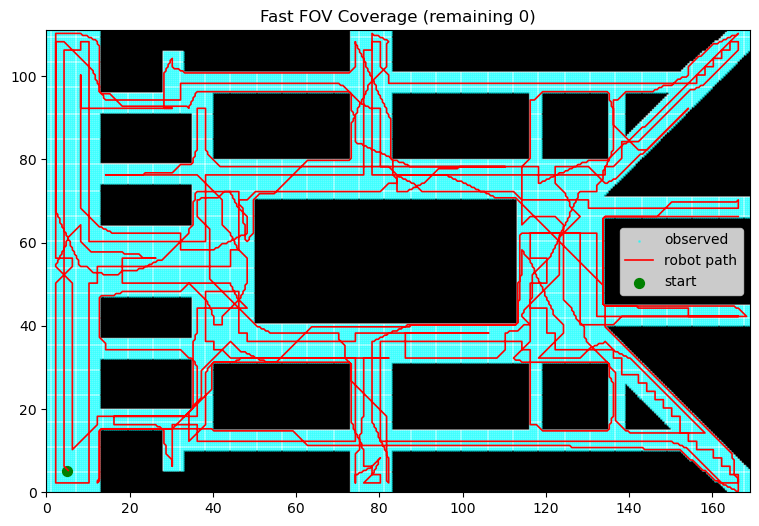

Total path length (m): 4430.297690045638


In [ ]:
# 원본 Untitled7.ipynb의 저장된 실행 결과를 보존한 셀입니다.

### 보고서의 평가와 해석

| 평가 항목 | 보고서 수치 | 해석 및 적용 범위 |
|---|---|---|
| 순찰 시간 | 약 4,198초, 약 70분 | 거리 ÷ 평균 속도 1.0556 m/s에 따른 추정 |
| 경로 기록 / 고유 방문 | 8,343 / 7,348 | 보고서 기재 수치이며 원본 저장 출력에는 이 두 값이 별도로 없음 |
| 경로 중복률 | 약 11.926% | (8,343 − 7,348) ÷ 8,343 × 100, 시작점 포함 여부 등 집계 기준 확인 필요 |
| 감시 커버리지 | 100% | 구현한 시야 모델에서 모든 자유 셀을 한 번 이상 관측 |
| 1회 배터리 소모 | 약 16.66% | 완충 7시간 가정에 따른 단순 시간 비례 추정 |

거리 4,430.29769 m와 속도 1.0556 m/s를 직접 적용하면 약 **4,196.95초(69.95분)**입니다. 보고서의 약 4,198초는 근사값으로 보존했습니다. 완충 7시간 가정에서 단순 비례한 소모율은 약 **16.65%**이나 배터리 실측값은 아닙니다.

원본 결과는 해당 모델에서 관측 누락이 없음을 보여줍니다. 다만 기존 외곽 순찰 경로를 같은 조건에서 실행한 기준선 실험이 포함되지 않아, 기존 대비 거리·시간·감시 효율의 개선율을 정량적으로 확정할 수는 없습니다.

## 7. 한계, 개선 방향 및 의의

### 현재 구현의 범위와 한계
- **점 형태의 로봇 모델:** 로봇 폭과 장애물 여유 거리를 반영하지 않았습니다. 대각선 이동에서 인접 장애물 모서리 사이를 통과하는 경우도 별도로 제한하지 않습니다.
- **이동 거리 중심 비용:** 회전, 가속, 감속, 정지, 배터리 소비를 목적함수에 직접 반영하지 않습니다.
- **정적 환경:** 보행자·이동 차량, 조도·기상 변화, 실시간 위치 추정과 장애물 회피를 구현하지 않았습니다.
- **누적 관측:** 한 번이라도 관측한 셀을 누적하므로 모든 공간을 동시에 또는 일정 주기 안에 계속 감시한다는 의미는 아닙니다.

### 향후 개선 방향
1. 시선 차폐를 검사하고 로봇 크기에 맞게 장애물 영역을 확장합니다.
2. 기존 외곽 경로와 동일 조건에서 거리·시간·관측률을 비교합니다.
3. 회전·정지 시간, 에너지 소비, 복귀 경로와 충전 제약을 추가합니다.
4. 동적 장애물 대응, SLAM 지도 갱신, 지역 주행 계획과 연결합니다.
5. 보고서에서 제안한 개인정보 보호와 센서 융합을 실제 시스템 설계로 확장합니다.

### 프로젝트의 의의
실제 캠퍼스의 순찰 문제를 조사하고, 공간을 좌표와 격자로 모델링한 뒤 알고리즘 선택·구현·평가로 연결했습니다. 특히 ‘짧은 경로’와 ‘넓은 감시 범위’가 다른 목표임을 확인하고 FOV 기반 계획으로 확장했다는 점에 의미가 있습니다. 이 절차는 공원·산업 현장 등 다른 공간의 순찰 계획에도 응용할 수 있습니다.